**DSC680-T301 Applied Data Science**

**Week 4, Milestone 3**

**Kyle Gotzman**

October 4, 2026

# ZIP Code-Aware Sale Price Prediction

Final white paper. The sections follow the course template. Code cells reproduce the tables and figures. The figures are the illustrations, and they are not part of the narrative page count. The audience questions from the draft are answered at the end.


## Business Problem and Research Questions

Buyers, sellers, and agents need a price before an appraisal or an offer. A national median misses the point that an extra bathroom, or another hundred square feet, is worth a different amount in each market. Price the home too high and the deal stalls. Price it too low and the seller leaves money on the table. This paper is a screening estimate of observed sale price for homes that already sold, meant to sit beside recent comps.

Three questions follow. How accurately can beds, baths, living area, lot size, and ZIP predict sale price, using median absolute percent error (MdAPE) and mean absolute error (MAE)? How much does ZIP improve on a no-location model and on a ZIP-median baseline? Does error differ across California, Texas, and Florida, and between thin and deep ZIPs? I expected a location-aware model to win on MdAPE, and I expected higher error where a ZIP has few sales.


## Background / History

Hedonic models treat a house as a bundle of attributes and estimate what buyers paid for each one (Rosen, 1974). Agents already do a simple version: take recent sales in the ZIP, then adjust for size and baths. The practical question is when those comps are too thin to trust. Sales here run from October 18, 2021, through May 6, 2022. The fit describes that window. Used as-is in a later year, it would still be a 2022 number.


## Data Explanation

The source is Sakib's (n.d.) USA Real Estate Dataset, Realtor.com-style listings in `realtor-data.zip.csv` (2,226,382 rows). I kept sold rows (812,009). The street id only drops duplicate listings. Sale date sets the window and breaks ties. Neither is a predictor.

The cleaning rules, in order, are in the next cell.

- Drop sold rows missing price, beds, baths, lot size, living area, ZIP, city, state, or street (203,533 rows, about 25%).
- Keep prices from \$10,000 to \$5,000,000, beds and baths from 1 to 8, living area from 400 to 8,000 square feet, and lots up to 10 acres.
- When the same street id and ZIP repeat, keep the later sale date (132 rows removed).

The analysis sample is 594,292 sales in 51 areas. The median home sold for \$369,900, with 1,730 square feet, 3 bedrooms, 2 bathrooms, and 0.19 acres. Median price per square foot was about \$198 overall, \$452 in California, \$203 in Florida, and \$163 in Texas (Figure 2).

A random 80/20 split (seed 42) gives 475,282 training rows and 119,010 test rows. ZIP medians and counts come from the training rows only. The 0.7% of test homes in an unseen ZIP get the national training median (\$369,900). Headline metrics use 104,820 test homes in ZIPs with at least 20 training sales. The other 14,190 are the sparse-ZIP check. Models fit log price because dollar price is right-skewed (Figure 1) and are scored in dollars. The appendix holds the data dictionary.

Those filters change who is in the sample. Sold rows missing price, beds, baths, lot size, living area, ZIP, or state are about 25% of sold listings. Their median price is about \$249,000, against about \$370,000 for complete cases. Florida is about 17% of those incomplete rows and about 9% of the complete rows. California is about 11% of the incomplete rows and about 17% of the complete rows. After the house-level caps, homes in ZIPs with fewer than 20 sales in the cleaned file are about 9% of what remains. Their median price is about \$250,000, against about \$380,000 in ZIPs with 20 or more sales, and California is about 5% of that thin group versus about 18% of the dense group. The headline error rates describe documented houses in deeper, higher-priced ZIPs. The next cell prints this comparison.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold

RANDOM_STATE = 42
TEST_SIZE = 0.20
MIN_ZIP_TRAIN = 20
HGB_FEATURES = ["bed", "bath", "log_sqft", "log_acre", "log_zip_med"]
NO_LOC_FORMULA = "log_price ~ bed + bath + log_sqft + log_acre"
LOC_FORMULA = "log_price ~ bed + bath + log_sqft + log_acre + log_zip_med"

DATA_PATH = Path("../realtor-data.zip.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("realtor-data.zip.csv")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 12, "axes.labelsize": 11})


def load_sold(path):
    columns = [
        "status", "price", "bed", "bath", "acre_lot", "street",
        "city", "state", "zip_code", "house_size", "prev_sold_date",
    ]
    frame = pd.read_csv(path, usecols=columns)
    sold = frame.loc[frame["status"] == "sold"].copy()
    sold["prev_sold_date"] = pd.to_datetime(sold["prev_sold_date"], errors="coerce")
    return sold


def clean_sold(sold):
    """Documented houses inside a plausible single-family range."""
    funnel = {"sold_rows": int(len(sold))}
    frame = sold.dropna(
        subset=["price", "bed", "bath", "acre_lot", "house_size", "zip_code", "state", "city", "street"]
    ).copy()
    funnel["complete_cases"] = int(len(frame))

    frame = frame.loc[frame["prev_sold_date"].notna() & (frame["prev_sold_date"].dt.year <= 2022)]
    funnel["valid_sale_date"] = int(len(frame))

    frame = frame.loc[frame["price"].between(10_000, 5_000_000)]
    funnel["price_10k_to_5m"] = int(len(frame))

    frame = frame.loc[frame["bed"].between(1, 8) & frame["bath"].between(1, 8)]
    funnel["beds_baths_1_to_8"] = int(len(frame))

    frame = frame.loc[frame["house_size"].between(400, 8_000)]
    funnel["house_size_400_to_8000"] = int(len(frame))

    frame = frame.loc[(frame["acre_lot"] > 0) & (frame["acre_lot"] <= 10)]
    funnel["lot_under_10_acres"] = int(len(frame))

    frame = frame.sort_values("prev_sold_date")
    before = len(frame)
    frame = frame.drop_duplicates(subset=["street", "zip_code"], keep="last")
    funnel["unique_street_zip"] = int(len(frame))
    funnel["duplicate_street_zip_removed"] = int(before - len(frame))

    frame["zip_code"] = frame["zip_code"].astype(int).astype(str).str.zfill(5)
    frame["log_price"] = np.log(frame["price"])
    frame["log_sqft"] = np.log(frame["house_size"])
    frame["log_acre"] = np.log(frame["acre_lot"])
    frame["ppsqft"] = frame["price"] / frame["house_size"]
    return frame.reset_index(drop=True), funnel


def add_location_features(train, test):
    """ZIP median and ZIP count are fit on the training rows only."""
    zip_median = train.groupby("zip_code")["price"].median()
    zip_n = train.groupby("zip_code").size()
    global_median = float(train["price"].median())

    def _apply(frame):
        out = frame.copy()
        mapped = out["zip_code"].map(zip_median)
        out["zip_n_train"] = out["zip_code"].map(zip_n).fillna(0).astype(int)
        out["zip_median_price"] = mapped.fillna(global_median)
        out["zip_median_missing"] = mapped.isna()
        out["log_zip_med"] = np.log(out["zip_median_price"])
        return out

    return _apply(train), _apply(test), global_median


def metrics(y_true, y_pred):
    error = y_pred - y_true
    ape = np.abs(error) / y_true
    return {
        "n": int(len(y_true)),
        "MdAPE": float(np.median(ape) * 100),
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "R2": float(1 - np.sum(error**2) / np.sum((y_true - np.mean(y_true)) ** 2)),
        "median_pred_over_actual": float(np.median(y_pred / y_true)),
    }


def fit_ols(train, formula):
    return smf.ols(formula, data=train).fit()


def predict_ols(model, frame):
    return np.exp(model.predict(frame).to_numpy())


def fit_hgb(train):
    # No early stopping, so this model sees the same rows as the regressions.
    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.08,
        max_depth=6,
        min_samples_leaf=40,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=RANDOM_STATE,
    )
    model.fit(train[HGB_FEATURES], train["log_price"])
    return model


def predict_hgb(model, frame):
    return np.exp(model.predict(frame[HGB_FEATURES]))


def zip_bin(counts):
    return pd.cut(
        counts,
        bins=[-0.1, 9, 19, 49, 99, np.inf],
        labels=["Under 10", "10-19", "20-49", "50-99", "100+"],
    )


def market_group(state):
    keep = {"California", "Texas", "Florida"}
    return state.where(state.isin(keep), "All other states")


sold = load_sold(DATA_PATH)
clean, funnel = clean_sold(sold)
funnel_table = pd.Series(funnel, name="rows")
display(funnel_table.to_frame())
print(
    f"Window {clean['prev_sold_date'].min().date()} to {clean['prev_sold_date'].max().date()}"
)
print(
    f"Median price ${clean['price'].median():,.0f}, "
    f"sqft {clean['house_size'].median():,.0f}, "
    f"beds {clean['bed'].median():.0f}, baths {clean['bath'].median():.0f}, "
    f"acres {clean['acre_lot'].median():.2f}"
)
print(f"Median price per sqft ${clean['ppsqft'].median():,.0f}")


Matplotlib is building the font cache; this may take a moment.


,rows
sold_rows,812009
complete_cases,608476
valid_sale_date,608476
price_10k_to_5m,606831
beds_baths_1_to_8,605234
house_size_400_to_8000,604319
lot_under_10_acres,594424
unique_street_zip,594292
duplicate_street_zip_removed,132


Window 2021-10-18 to 2022-05-06
Median price $369,900, sqft 1,730, beds 3, baths 2, acres 0.19
Median price per sqft $198


In [2]:
need = ["price", "bed", "bath", "acre_lot", "house_size", "zip_code", "state"]
complete_mask = sold[need].notna().all(axis=1)
incomplete = sold.loc[~complete_mask]
complete_rows = sold.loc[complete_mask]
print(
    f"Incomplete rows: {len(incomplete):,} "
    f"({100 * len(incomplete) / len(sold):.1f}% of sold)"
)
print(
    f"Median price, incomplete ${incomplete['price'].median():,.0f}, "
    f"complete ${complete_rows['price'].median():,.0f}"
)
for label, part in [("incomplete", incomplete), ("complete", complete_rows)]:
    shares = part["state"].value_counts(normalize=True)
    print(
        label,
        "CA", f"{100 * shares.get('California', 0):.1f}%",
        "FL", f"{100 * shares.get('Florida', 0):.1f}%",
        "TX", f"{100 * shares.get('Texas', 0):.1f}%",
    )

zip_counts = clean.groupby("zip_code").size()
clean = clean.copy()
clean["zip_n_file"] = clean["zip_code"].map(zip_counts)
thin = clean.loc[clean["zip_n_file"] < 20]
dense_file = clean.loc[clean["zip_n_file"] >= 20]
print(
    f"Cleaned homes in ZIPs with fewer than 20 sales: {len(thin):,} "
    f"({100 * len(thin) / len(clean):.1f}%)"
)
for label, part in [("thin ZIPs", thin), ("dense ZIPs", dense_file)]:
    shares = part["state"].value_counts(normalize=True)
    print(
        label,
        f"median ${part['price'].median():,.0f}",
        "CA", f"{100 * shares.get('California', 0):.1f}%",
    )


Incomplete rows: 202,233 (24.9% of sold)
Median price, incomplete $249,000, complete $370,000
incomplete CA 10.6% FL 16.7% TX 6.0%
complete CA 17.0% FL 8.5% TX 11.2%
Cleaned homes in ZIPs with fewer than 20 sales: 54,968 (9.2%)
thin ZIPs median $250,000 CA 4.8%


dense ZIPs median $379,900 CA 18.2%


**Figure 1.** Distribution of sale price in the cleaned sample. Dollar price is right-skewed, so the models fit log price and are scored in dollars.


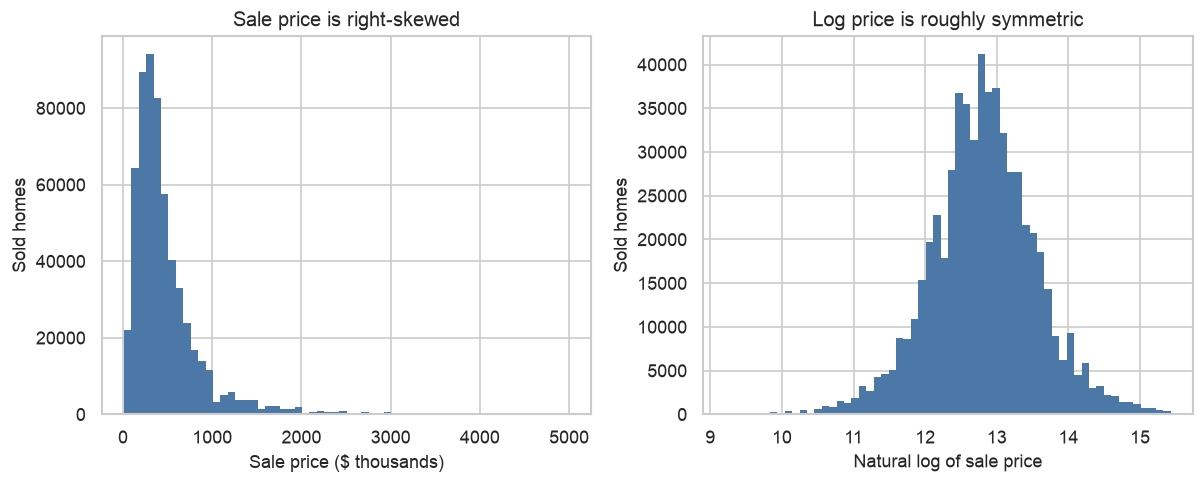

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.2))
axes[0].hist(clean["price"] / 1000, bins=60, color="#4C78A8", edgecolor="none")
axes[0].set_xlabel("Sale price ($ thousands)")
axes[0].set_ylabel("Sold homes")
axes[0].set_title("Sale price is right-skewed")
axes[1].hist(clean["log_price"], bins=60, color="#4C78A8", edgecolor="none")
axes[1].set_xlabel("Natural log of sale price")
axes[1].set_ylabel("Sold homes")
axes[1].set_title("Log price is roughly symmetric")
fig.tight_layout()
plt.show()


**Figure 2.** Sale price per square foot by market. Boxes show the middle half of homes. Extreme values are hidden so the markets can be compared. California's center sits far above Texas, Florida, and the other states.


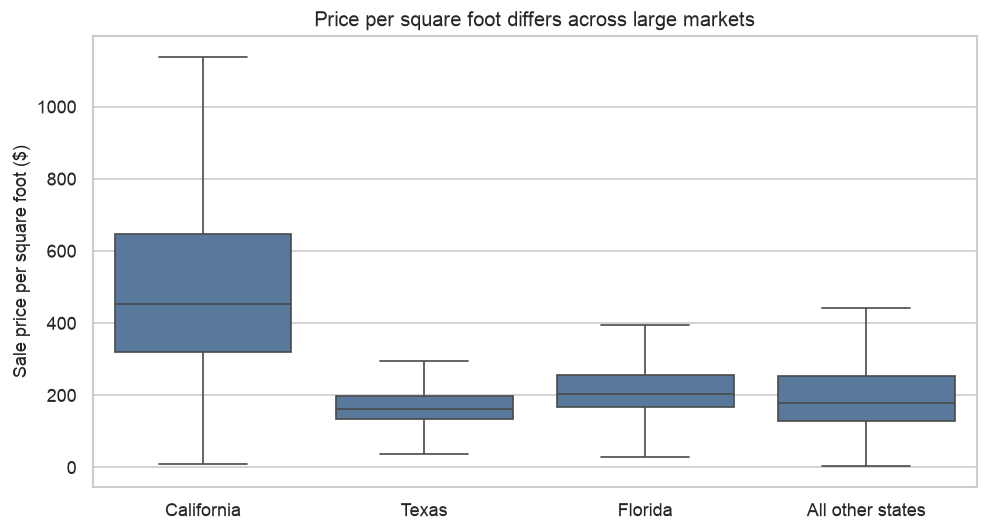

In [4]:
plot_df = clean.copy()
plot_df["market"] = market_group(plot_df["state"])
fig, ax = plt.subplots(figsize=(8.4, 4.6))
sns.boxplot(
    data=plot_df,
    x="market",
    y="ppsqft",
    order=["California", "Texas", "Florida", "All other states"],
    showfliers=False,
    color="#4C78A8",
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Sale price per square foot ($)")
ax.set_title("Price per square foot differs across large markets")
fig.tight_layout()
plt.show()


## Methods

Five predictors are scored on the same test homes. The baselines are the national training median and the training median inside the home's ZIP. Two ordinary least squares models fit log price: one on beds, baths, log living area, and log lot size, and one that also includes the log training ZIP median. Histogram gradient boosting uses those same five inputs (200 iterations, learning rate 0.08, depth 6, minimum leaf 40).

A regression per ZIP does not fit this file. Only 5,697 of 16,765 training ZIPs have 20 or more sales. A huge set of ZIP indicator columns would still fail when a ZIP is new at scoring time. The proposal named a random forest. Boosting is the same tree-ensemble idea and fits this sample quickly. The linear model stays so the bathroom and size adjustments are visible once the ZIP price level is held fixed. Boosting can bend those adjustments. I exponentiate the log predictions, so MdAPE is the headline score and MAE sits beside it.

The holdout is a random 20% of cleaned sales. Five-fold cross-validation on the training set rebuilds the ZIP median inside each training fold, so that feature never sees the rows being scored. I report MAE, root mean squared error, MdAPE, and dollar R-squared. The target is a continuous price.


In [5]:
rng = np.random.default_rng(RANDOM_STATE)
train_mask = rng.random(len(clean)) >= TEST_SIZE
train = clean.loc[train_mask].copy()
test = clean.loc[~train_mask].copy()
train, test, global_median = add_location_features(train, test)

ols_no = fit_ols(train, NO_LOC_FORMULA)
ols_loc = fit_ols(train, LOC_FORMULA)
hgb = fit_hgb(train)

test = test.copy()
test["pred_global"] = global_median
test["pred_zip"] = test["zip_median_price"]
test["pred_ols_no"] = predict_ols(ols_no, test)
test["pred_ols_loc"] = predict_ols(ols_loc, test)
test["pred_hgb"] = predict_hgb(hgb, test)
test["zip_bin"] = zip_bin(test["zip_n_train"])
test["market"] = market_group(test["state"])

pred_cols = {
    "Global median": "pred_global",
    "ZIP median": "pred_zip",
    "Hedonic, no location": "pred_ols_no",
    "Hedonic + ZIP median": "pred_ols_loc",
    "Gradient boosting + ZIP median": "pred_hgb",
}
dense = test["zip_n_train"] >= MIN_ZIP_TRAIN
test_dense = test.loc[dense].copy()

holdout_rows = []
for name, column in pred_cols.items():
    row = metrics(test_dense["price"].to_numpy(), test_dense[column].to_numpy())
    row["model"] = name
    holdout_rows.append(row)
holdout = pd.DataFrame(holdout_rows)
display(holdout[["model", "n", "MdAPE", "MAE", "RMSE", "R2"]].round(3))


def cross_validate(train_frame):
    """Five-fold MdAPE. ZIP medians are refit inside each training fold."""
    folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for fold, (tr_index, va_index) in enumerate(folds.split(train_frame), start=1):
        tr = train_frame.iloc[tr_index]
        va = train_frame.iloc[va_index]
        tr_f, va_f, _ = add_location_features(tr, va)
        scored = va_f.loc[va_f["zip_n_train"] >= MIN_ZIP_TRAIN]
        y = scored["price"].to_numpy()
        fold_median = float(tr_f["price"].median())
        ols_fold_no = fit_ols(tr_f, NO_LOC_FORMULA)
        ols_fold_loc = fit_ols(tr_f, LOC_FORMULA)
        hgb_fold = fit_hgb(tr_f)
        named = {
            "Global median": np.full(len(scored), fold_median),
            "ZIP median": scored["zip_median_price"].to_numpy(),
            "Hedonic, no location": predict_ols(ols_fold_no, scored),
            "Hedonic + ZIP median": predict_ols(ols_fold_loc, scored),
            "Gradient boosting + ZIP median": predict_hgb(hgb_fold, scored),
        }
        for name, pred in named.items():
            scored_metrics = metrics(y, pred)
            rows.append({"fold": fold, "model": name, "MdAPE": scored_metrics["MdAPE"], "MAE": scored_metrics["MAE"]})
        print(f"fold {fold} done")
    return pd.DataFrame(rows)


cv = cross_validate(train)
cv_summary = (
    cv.groupby("model", as_index=False)
    .agg(MdAPE_mean=("MdAPE", "mean"), MdAPE_sd=("MdAPE", "std"), MAE_mean=("MAE", "mean"))
    .sort_values("MdAPE_mean")
)
display(cv_summary.round(3))


,model,n,MdAPE,MAE,RMSE,R2
0,Global median,104820,41.660,261419.068,473306.441,-0.086
1,ZIP median,104820,20.738,144456.304,283135.007,0.612
2,"Hedonic, no location",104820,36.477,224948.667,405300.042,0.204
3,Hedonic + ZIP median,104820,16.204,107792.259,207788.777,0.791
4,Gradient boosting + ZIP median,104820,14.760,99473.332,198201.992,0.810


fold 1 done


fold 2 done


fold 3 done


fold 4 done


fold 5 done


,model,MdAPE_mean,MdAPE_sd,MAE_mean
1,Gradient boosting + ZIP median,14.663,0.104,99624.732
2,Hedonic + ZIP median,16.230,0.088,108518.712
4,ZIP median,20.590,0.079,144593.254
3,"Hedonic, no location",36.522,0.067,226197.731
0,Global median,41.609,0.347,262572.926


**Figure 3.** Holdout accuracy for test homes in ZIPs with at least 20 training sales (*n* = 104,820). Lower is better. Gradient boosting with a training-set ZIP median has the smallest typical percent error and the smallest average dollar error.


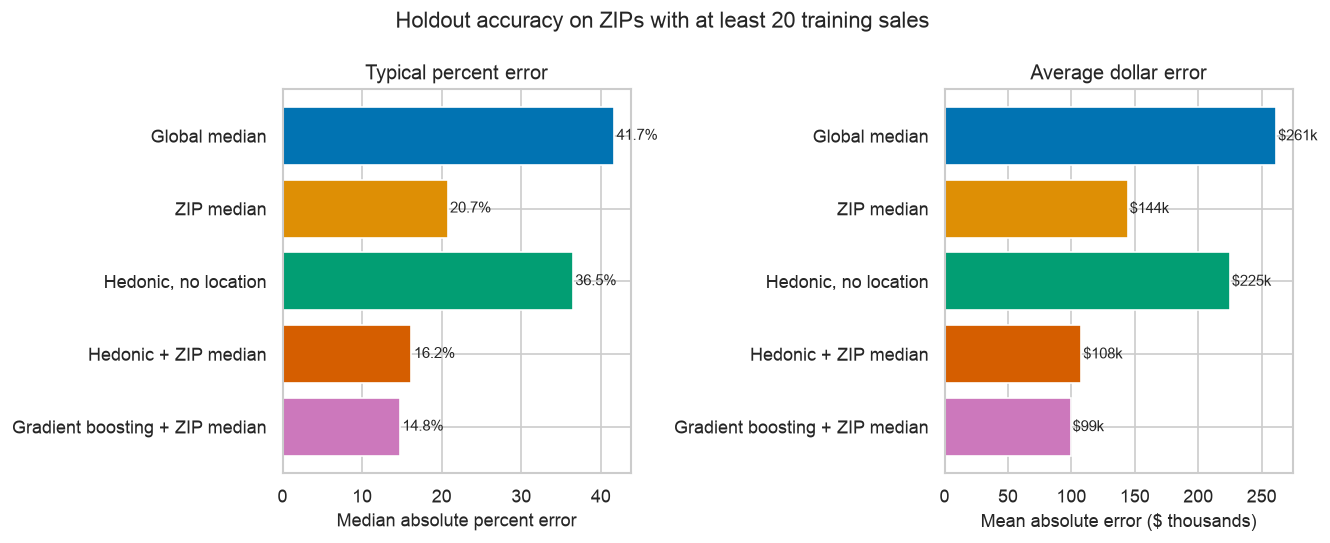

In [6]:
order = [
    "Global median",
    "ZIP median",
    "Hedonic, no location",
    "Hedonic + ZIP median",
    "Gradient boosting + ZIP median",
]
colors = sns.color_palette("colorblind", n_colors=len(order))
color_map = dict(zip(order, colors))
plot_c = holdout.set_index("model").loc[order].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6))
axes[0].barh(plot_c["model"], plot_c["MdAPE"], color=[color_map[m] for m in plot_c["model"]])
axes[0].invert_yaxis()
axes[0].set_xlabel("Median absolute percent error")
axes[0].set_title("Typical percent error")
for i, val in enumerate(plot_c["MdAPE"]):
    axes[0].text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=9)
axes[1].barh(plot_c["model"], plot_c["MAE"] / 1000, color=[color_map[m] for m in plot_c["model"]])
axes[1].invert_yaxis()
axes[1].set_xlabel("Mean absolute error ($ thousands)")
axes[1].set_title("Average dollar error")
for i, val in enumerate(plot_c["MAE"] / 1000):
    axes[1].text(val + 1.5, i, f"${val:.0f}k", va="center", fontsize=9)
fig.suptitle("Holdout accuracy on ZIPs with at least 20 training sales", fontsize=13)
fig.tight_layout()
plt.show()


## Analysis

On ZIPs with at least 20 training sales, the national median misses by 41.7% (MAE about \$261,000). Structure without location reaches 36.5% (MAE about \$225,000). The ZIP median alone reaches 20.7% (MAE about \$144,000). Structure plus that median reaches 16.2% (MAE about \$108,000, dollar R-squared = 0.79). Boosting reaches 14.8% (MAE about \$99,000, dollar R-squared = 0.81; Figure 3). Cross-validation MdAPE for boosting averaged 14.7% (SD 0.1 point), so the ranking is not one lucky split.

The ZIP median does most of the work. Log-price R-squared rises from 0.31 to 0.83 when it is added, and its elasticity is 0.92. Holding ZIP level and living area fixed, an extra bathroom lines up with about a 7% higher price and an extra bedroom with about 1%. Ten percent more living area lines up with about 4.7% more price. The lot elasticity is 0.035. These are sample associations with the other covariates held fixed. Without ZIP, the bedroom coefficient flips to about -4%: more bedrooms in a fixed footprint means smaller rooms, and bedrooms were standing in for cheaper markets.

The coefficients below are on the log-price scale. For beds and baths, the approximate percent change is exp(*b*) - 1. For the log terms, the coefficient is an elasticity.


In [7]:
coef = pd.DataFrame({
    "term": ols_loc.params.index,
    "coef": ols_loc.params.values,
    "std_err": ols_loc.bse.values,
})
coef_no = pd.DataFrame({
    "term": ols_no.params.index,
    "coef": ols_no.params.values,
    "std_err": ols_no.bse.values,
})
print(f"Log-price R-squared, no location: {ols_no.rsquared:.3f}")
print(f"Log-price R-squared, with ZIP median: {ols_loc.rsquared:.3f}")
print("With ZIP median")
display(coef.round(4))
print("Without location")
display(coef_no.round(4))


Log-price R-squared, no location: 0.305
Log-price R-squared, with ZIP median: 0.832
With ZIP median


,term,coef,std_err
0,Intercept,-2.6639,0.0150
1,bed,0.0128,0.0007
2,bath,0.0704,0.0007
3,log_sqft,0.4784,0.0019
4,log_acre,0.0350,0.0004
5,log_zip_med,0.9163,0.0008


Without location


,term,coef,std_err
0,Intercept,8.0784,0.0247
1,bed,-0.0437,0.0013
2,bath,0.2412,0.0014
3,log_sqft,0.5694,0.0038
4,log_acre,-0.0286,0.0008


Thin ZIPs are less accurate (Figure 4). Boosting MdAPE is 27.3% below 10 training sales, 19.7% at 10-19, 16.9% at 20-49, 15.6% at 50-99, and 13.5% at 100 or more. Both expectations hold: location-aware models beat the no-location model and the ZIP median, and sparse ZIPs should be flagged.

Boosting MdAPE on the dense slice is 12.7% in California, 15.3% in Texas, 16.4% in Florida, and 15.2% elsewhere (Figure 5). Structure without location misses California by 52.0%. The state's median sale is \$713,000, against \$315,000 in Texas, so a national anchor is far too low. The ZIP median alone brings California to 17.2%, though MAE is still about \$167,000 because prices are high. In Florida, structure without location (23.1%) ties the ZIP median, and boosting still reaches 16.4%.


In [8]:
by_zip_rows = []
for label, part in test.groupby("zip_bin", observed=True):
    for name, column in pred_cols.items():
        row = metrics(part["price"].to_numpy(), part[column].to_numpy())
        row["model"] = name
        row["zip_bin"] = str(label)
        by_zip_rows.append(row)
by_zip = pd.DataFrame(by_zip_rows)

by_market_rows = []
for market, part in test_dense.groupby("market"):
    for name, column in pred_cols.items():
        row = metrics(part["price"].to_numpy(), part[column].to_numpy())
        row["model"] = name
        row["market"] = market
        by_market_rows.append(row)
by_market = pd.DataFrame(by_market_rows)

focus = ["ZIP median", "Hedonic, no location", "Gradient boosting + ZIP median"]
print("MdAPE by training sales in the ZIP")
display(
    by_zip.loc[by_zip["model"].isin(focus)]
    .pivot(index="zip_bin", columns="model", values="MdAPE")
    .round(1)
)
print("MdAPE by market, ZIPs with at least 20 training sales")
display(
    by_market.loc[by_market["model"].isin(focus)]
    .pivot(index="market", columns="model", values="MdAPE")
    .round(1)
)


MdAPE by training sales in the ZIP


model,Gradient boosting + ZIP median,"Hedonic, no location",ZIP median
zip_bin,,,
10-19,19.7,40.5,25.8
100+,13.5,33.5,19.5
20-49,16.9,39.6,23.1
50-99,15.6,39.9,21.5
Under 10,27.3,52.3,35.1


MdAPE by market, ZIPs with at least 20 training sales


model,Gradient boosting + ZIP median,"Hedonic, no location",ZIP median
market,,,
All other states,15.2,34.5,21.6
California,12.7,52.0,17.2
Florida,16.4,23.1,23.1
Texas,15.3,30.4,20.6


**Figure 4.** Holdout median absolute percent error by how many training sales the home's ZIP contributed. The boosted model stays below the ZIP median, and every model is less accurate in thin ZIPs.


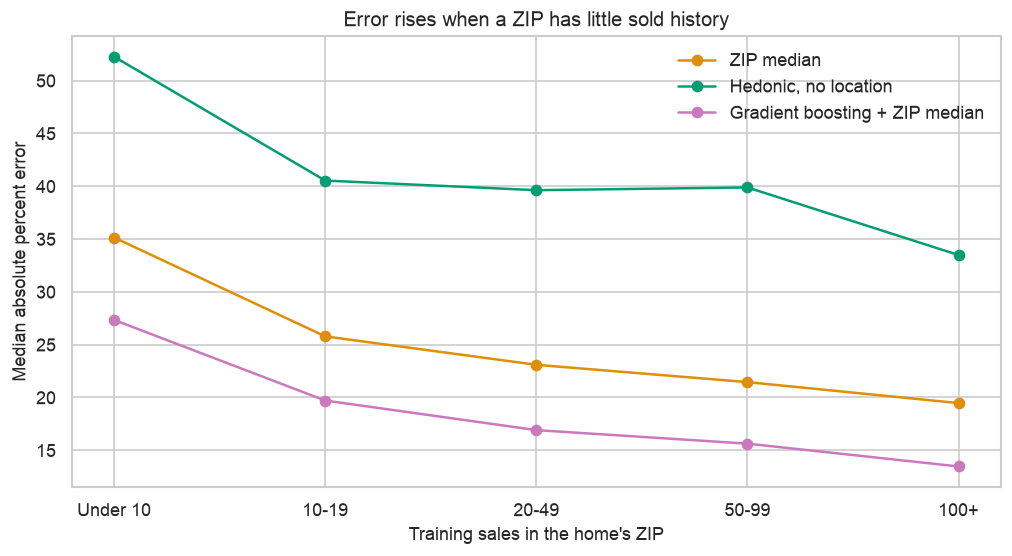

In [9]:
fig, ax = plt.subplots(figsize=(8.6, 4.8))
for name in focus:
    part = by_zip.loc[by_zip["model"] == name]
    ax.plot(part["zip_bin"].astype(str), part["MdAPE"], marker="o", label=name, color=color_map[name])
ax.set_xlabel("Training sales in the home's ZIP")
ax.set_ylabel("Median absolute percent error")
ax.set_title("Error rises when a ZIP has little sold history")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


**Figure 5.** Holdout median absolute percent error on ZIPs with at least 20 training sales, by market. A model with no location fails in California. Once ZIP is included, California's typical percent error is the lowest of these groups.


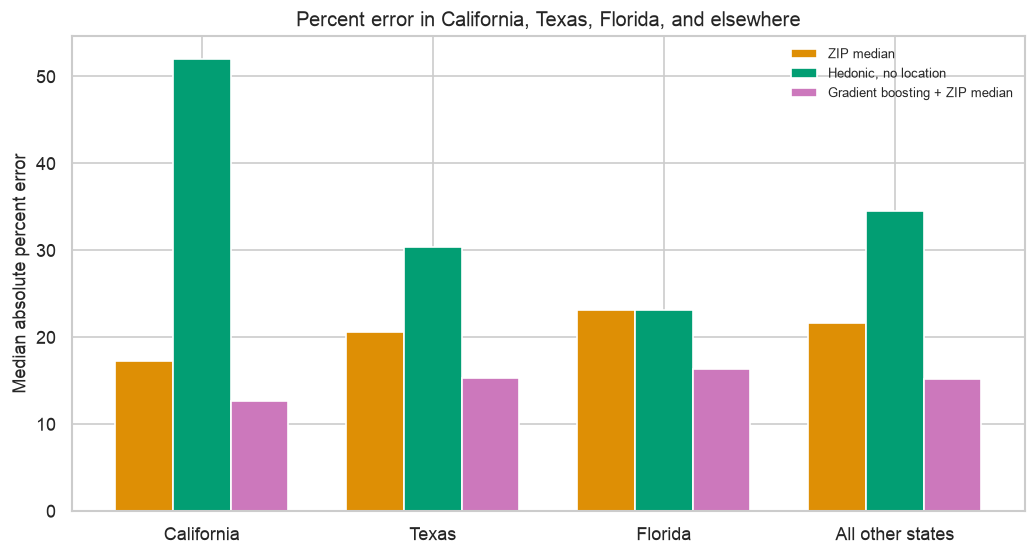

In [10]:
markets = ["California", "Texas", "Florida", "All other states"]
x = np.arange(len(markets))
width = 0.25
fig, ax = plt.subplots(figsize=(8.8, 4.8))
for i, name in enumerate(focus):
    part = by_market.loc[by_market["model"] == name].set_index("market").loc[markets]
    ax.bar(x + (i - 1) * width, part["MdAPE"], width=width, label=name, color=color_map[name])
ax.set_xticks(x)
ax.set_xticklabels(markets)
ax.set_ylabel("Median absolute percent error")
ax.set_title("Percent error in California, Texas, Florida, and elsewhere")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()


MdAPE is the middle miss. On the dense slice, 36% of boosted predictions fell within 10% of price and 63% within 20%. The 80th percentile miss was 30%. The cheapest fifth (up to \$224,900) has the worst percent error (MdAPE 21.0%). The top fifth (\$674,500 to \$5,000,000) has the worst dollar error (MAE about \$255,000). California and that top fifth are slightly underpredicted (median predicted/actual 0.94 and 0.91).


In [11]:
ape = np.abs(test_dense["pred_hgb"] - test_dense["price"]) / test_dense["price"]
print(f"Share within 10%: {(ape <= 0.10).mean():.1%}")
print(f"Share within 20%: {(ape <= 0.20).mean():.1%}")
print(f"80th percentile absolute percent error: {np.quantile(ape, 0.80):.1%}")

test_dense = test_dense.copy()
test_dense["price_q"] = pd.qcut(
    test_dense["price"], 5, labels=["Q1 lowest", "Q2", "Q3", "Q4", "Q5 highest"]
)
q_rows = []
for label, part in test_dense.groupby("price_q", observed=True):
    row = metrics(part["price"].to_numpy(), part["pred_hgb"].to_numpy())
    row["price_quintile"] = str(label)
    row["price_min"] = float(part["price"].min())
    row["price_max"] = float(part["price"].max())
    q_rows.append(row)
by_q = pd.DataFrame(q_rows)
display(
    by_q[["price_quintile", "n", "price_min", "price_max", "MdAPE", "MAE", "median_pred_over_actual"]].round(3)
)


Share within 10%: 35.5%
Share within 20%: 63.1%
80th percentile absolute percent error: 30.1%


,price_quintile,n,price_min,price_max,MdAPE,MAE,median_pred_over_actual
0,Q1 lowest,20997,10000.0,224900.0,20.987,44727.028,1.116
1,Q2,21198,224950.0,325000.0,13.587,48460.957,1.018
2,Q3,20739,325244.0,449000.0,12.490,61221.613,0.982
3,Q4,20929,449055.0,674000.0,12.963,87975.702,0.961
4,Q5 highest,20957,674500.0,5000000.0,16.065,255259.217,0.908


## Conclusion

Start from the ZIP's recent price level, then adjust for living area and bathrooms. A national model of beds and size does not solve the pricing problem. On ZIPs with at least 20 training sales, boosting is typically off by 14.8% and about \$99,000, and cross-validation matches that percent within a tenth of a point. ZIP information cuts typical error from 36.5% to 14.8%. Error is worse in thin ZIPs. California's percent error is the best of the large markets once ZIP is included, and the worst when location is left out. The estimate can flag a list price that sits far from comps. Thin ZIPs need a wider band.

## Assumptions

The sold price field is the target, taken as this file's recorded sale price. Homes missing beds, baths, or size are out of scope. The random split matches pricing a home in a ZIP that already has comps. Caps at \$5 million, 8,000 square feet, 8 beds, 8 baths, and 10 acres define the population. Log fits are exponentiated without a smearing correction, in line with MdAPE. The sale window is one regime, with no month effect.

## Limitations

There is no condition, year built, school quality, or coordinates, so a large residual is expected. The window ends in May 2022, and the fit will drift as rates and inventory change. Expensive homes pull MAE up. A ZIP median restates between-ZIP price gaps. Under 1% of test homes had an unseen ZIP and received the national median.

## Challenges

About a quarter of sold rows lacked beds, baths, or size. I dropped them and reported the share, rather than imputing structure. The raw file includes extremes such as a \$295 million price, so the caps are explicit. Only 132 duplicate street-and-ZIP rows remained after the sold filter. Few ZIPs have enough sales for their own model, so ZIP enters as a training-set median.

## Future Uses / Additional Applications

Refit the pipeline on a newer sold extract. Use a city or county median under the 20-sale floor. Year built, condition, or a school measure would show how much of the remaining error is house quality. The screen should show a range, not only a point, and it should show the training vintage.

## Recommendations

Start with the ZIP median, then adjust for living area and bathrooms. Quote the boosted estimate, as a range, when the ZIP has at least 20 reference sales. In California, start from California comps. Use the number as a list-price check beside comps. Refit before using it outside October 2021 through May 2022. Label the result low-confidence below 20 reference sales.

## Implementation Plan

The agent enters beds, baths, square feet, lot acres, and ZIP. The tool counts reference sales in that ZIP. At 20 or more it returns the boosted estimate, the ZIP median, and a band from this holdout: a typical miss of about 15%, about one in three misses larger than 20%, and about one in five larger than 30%. Below 20 sales it shows a low-confidence label and the sparse-ZIP error (about 20% MdAPE at 10-19 sales, about 27% below 10). The result carries the vintage October 18, 2021, through May 6, 2022.

## Ethical Assessment

**Overstating the estimate.** A user may drop the point estimate into an offer or a loan file. That is a realistic use, and the harm is serious: the typical miss is about 15%, and many misses are larger. This paper and any screen built from it should call the number a research estimate from public listings in a past window, a list-price check beside comps, and a poor stand-in for a licensed appraisal. It stays out of credit decisions.

**Thin ZIPs.** Any ZIP with little sold history will get a noisier number, with more impact in smaller markets that already lack comps. Headline error is limited to ZIPs with at least 20 training sales, Figure 4 publishes error by sample size, and the tool withholds a firm number below that floor. Boosting MdAPE was 27.3% under 10 training sales and 13.5% at 100 or more.

**Selection, source, and neighborhood levels.** Dropping the quarter of sold rows missing beds, baths, or size changes who is in the model. Those rows may be land, new construction, or incomplete listings, so every error rate in this paper is for documented houses inside the caps. The source is a public Kaggle compilation of Realtor.com-style listings (Sakib, n.d.). I did not match rows to closing statements. Street ids stay anonymized, and this paper does not publish address-level records. The ZIP median also restates neighborhood price levels, which can track income and historically segregated housing. Putting that feature into a lending or insurance decision would be a serious misuse. ZIP stays a market control for a pricing screen, the coefficient is described as a restatement of local prices, and the model stays away from credit. Every filter is in the data section and the code cell that builds the sample.

## Code and Reproducibility

This notebook is the canonical analysis. From the `WK4` folder, with `realtor-data.zip.csv` in the repository root, run all cells. Download instructions are in `data/README.md`. The same run produces the cleaning funnel, the model comparison, the cross-validation, Figures 1 through 5, and the appendix figure.


## Appendix: Supporting Documentation

### Data Dictionary

**price.** Sale price in dollars for rows with status = sold. Fitting target after a log transform.

**bed, bath.** Bedroom and bathroom counts. Predictors.

**house_size.** Living area in square feet. Entered as a log.

**acre_lot.** Lot size in acres. Entered as a log.

**zip_code.** Five-digit ZIP. Used to attach a median price and a sale count from the training fold.

**city, state.** Geography for description and for the California, Texas, and Florida slices.

**prev_sold_date.** Sale date. Used for the window and for keeping the later duplicate. Not a predictor.

**street.** Anonymized id. Used only to drop duplicate street-and-ZIP rows.

**status.** Listing status. Only sold rows enter the sample.

**Appendix Figure.** Boosted predictions against actual sale price for an 8,000-home sample of the dense-ZIP holdout. The diagonal is perfect prediction. Spread widens as price rises, which matches the larger dollar errors in the top price fifth.


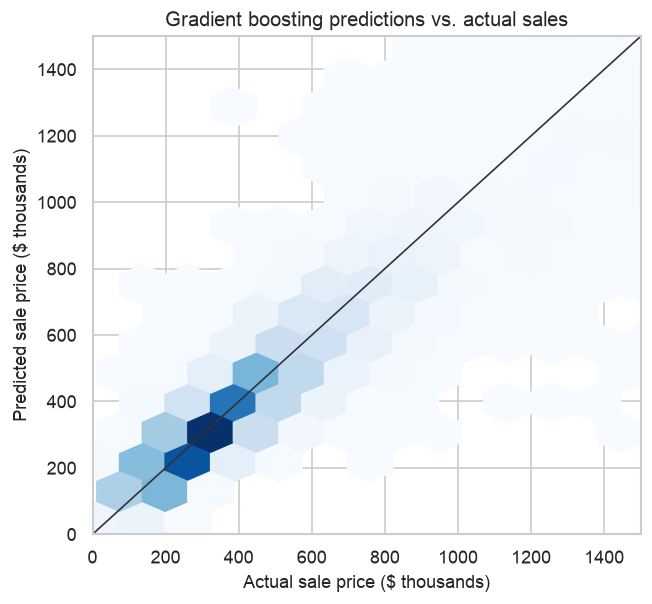

In [12]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
sample = test_dense.sample(n=min(8000, len(test_dense)), random_state=RANDOM_STATE)
ax.hexbin(sample["price"] / 1000, sample["pred_hgb"] / 1000, gridsize=40, cmap="Blues", mincnt=1)
lim = 1500
ax.plot([0, lim], [0, lim], color="#333333", linewidth=1)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("Actual sale price ($ thousands)")
ax.set_ylabel("Predicted sale price ($ thousands)")
ax.set_title("Gradient boosting predictions vs. actual sales")
fig.tight_layout()
plt.show()


## Ten Questions an Audience Would Ask

1. **Why fit the model on sold prices instead of asking prices?** Sold price is the outcome an offer has to survive. An asking price is still a wish. Homes that are only listed would answer a different question, so `for_sale` rows stay out of the fit.

2. **How should an agent use a tool whose typical miss is about 15%?** Use it as a range next to comps. A typical miss on a deep ZIP is about 15%, and about one in three estimates misses by more than 20%. If the list price sits far outside that range, pull comps. Do not write the offer from the point estimate.

3. **Is the ZIP median leakage, since it is built from sale prices?** It is not leakage across the test set. The median is computed from training sales only, and the five-fold check rebuilds it inside each training fold. A scored home's own price is not in its ZIP feature. The feature is other homes in that ZIP, which is what comps are.

4. **What should the screen show for a ZIP with only eight sales?** Withhold a firm number. Under 10 training sales the typical miss was about 27%, and at 10 to 19 sales it was about 20%. Label the ZIP low-confidence, or roll the comps up to a wider geography.

5. **Why is an extra bedroom worth so little once square footage and ZIP are in the model?** With living area held fixed, another bedroom mostly means smaller rooms. In the location-aware regression that association is about 1%. Without ZIP, the bedroom coefficient was negative, about -4%, because bedroom count was standing in for cheaper markets.

6. **Why does a national model miss California by so much, while the ZIP-aware model looks better there on a percent basis?** California's median sale in this file is \$713,000, against \$315,000 in Texas. A national anchor is far too low, so the no-location model misses California by about 52%. Once the ZIP median sets the local price level, California's typical percent error is 12.7%, the best of the large markets. Dollar error stays large, about \$167,000, because the homes cost more.

7. **Would these error rates still hold on 2026 sales?** No. The fit is October 18, 2021, through May 6, 2022. Rates and inventory have moved. Refit on a current sold window before using the screen. The method can be reused. The 15% figure belongs to that window.

8. **How much of the remaining error is condition, year built, or schools?** This file cannot say. Those fields are absent, and that missing information is a large part of why a 15% miss remains after ZIP and size are included. Adding them is the useful next test.

9. **What keeps this ZIP adjustment from being reused in a lending decision?** The ZIP median restates neighborhood price levels. Those levels track income, and historically they track segregated housing. Using that feature in a credit or insurance decision would treat a market control as a statement about people. Keep it as a comps screen. Keep it out of credit.

10. **Why one national model with a ZIP feature, instead of a separate model for each ZIP?** Most ZIPs do not have enough sales for their own model. Only 5,697 of 16,765 training ZIPs reach 20 sales. One model with a training-set ZIP median borrows strength across markets and still adjusts inside the ZIP. Thin ZIPs stay labeled low-confidence instead of getting a noisy local fit.

## References

Rosen, S. (1974). Hedonic prices and implicit markets: Product differentiation in pure competition. *Journal of Political Economy, 82*(1), 34-55. https://doi.org/10.1086/260169

Sakib, A. S. (n.d.). *USA real estate dataset*. Kaggle. https://www.kaggle.com/datasets/ahmedshahriarsakib/usa-real-estate-dataset
